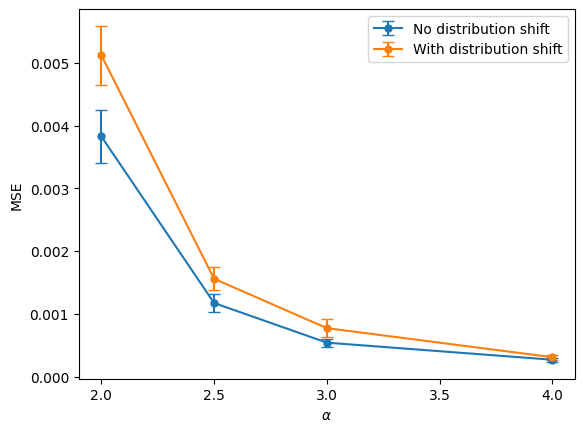

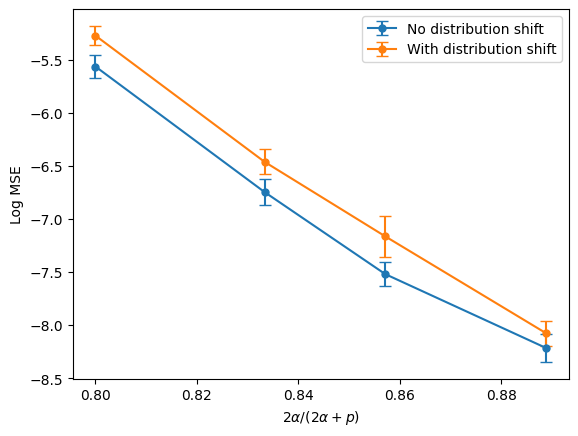

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

test = pd.read_csv("test_results.csv")
loss = np.array([np.mean(test['alpha_4']), np.mean(test['alpha_3']), np.mean(test['alpha_2_5']), np.mean(test['alpha_2'])])
log_loss = np.log(loss)
loss_se = np.array([np.std(test['alpha_4'])/np.sqrt(len(test['alpha_4'])), np.std(test['alpha_3'])/np.sqrt(len(test['alpha_3'])), np.std(test['alpha_2_5'])/np.sqrt(len(test['alpha_2_5'])), np.std(test['alpha_2'])/np.sqrt(len(test['alpha_2']))])
log_loss_se = loss_se / loss

test_ds = pd.read_csv("test_results_ds.csv")
loss_ds = np.array([np.mean(test_ds['alpha_4']), np.mean(test_ds['alpha_3']), np.mean(test_ds['alpha_2_5']), np.mean(test_ds['alpha_2'])])
log_loss_ds = np.log(loss_ds)
loss_se_ds = np.array([np.std(test_ds['alpha_4'])/np.sqrt(len(test_ds['alpha_4'])), np.std(test_ds['alpha_3'])/np.sqrt(len(test_ds['alpha_3'])), np.std(test_ds['alpha_2_5'])/np.sqrt(len(test_ds['alpha_2_5'])), np.std(test_ds['alpha_2'])/np.sqrt(len(test_ds['alpha_2']))])
log_loss_se_ds = loss_se_ds / loss_ds


plt.figure()
plt.errorbar(
    [4, 3, 2.5, 2],
    loss,
    yerr=1.645*loss_se,
    fmt='o-',
    capsize=4,
    markersize=5,
    label='No distribution shift'
)
plt.errorbar(
    [4, 3, 2.5, 2],
    loss_ds,
    yerr=1.645*loss_se_ds,
    fmt='o-',
    capsize=4,
    markersize=5,
    label='With distribution shift'
)
plt.legend()
plt.xlabel(r'$\alpha$')
plt.xticks([2.0, 2.5, 3.0, 3.5, 4.0])
plt.ylabel('MSE')
plt.savefig("loss.pdf", bbox_inches='tight')
plt.show()

exponent = [8/9, 6/7, 5/6, 4/5]   # value of 2a/(2a + p)
plt.figure()
plt.errorbar(
    exponent,
    log_loss,
    yerr=1.645*log_loss_se,
    fmt='o-',
    capsize=4,
    markersize=5,
    label='No distribution shift'
)
plt.errorbar(
    exponent,
    log_loss_ds,
    yerr=1.645*log_loss_se_ds,
    fmt='o-',
    capsize=4,
    markersize=5,
    label='With distribution shift'
)
plt.legend()
plt.xlabel(r'$2\alpha/(2\alpha + p)$')
plt.ylabel('Log MSE')
plt.savefig("log_loss.pdf", bbox_inches='tight')
plt.show()